# Data pre-processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = "../../data/graduation_dataset.csv"
df = pd.read_csv(DATA_PATH)
df.shape

(4424, 35)

In [2]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,10,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,10,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


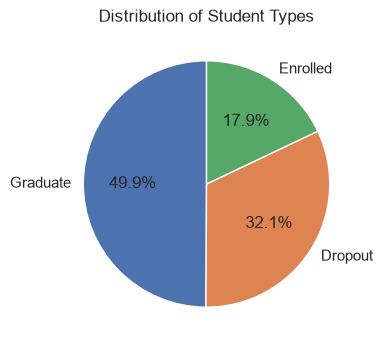

In [3]:
counts = df['Target'].value_counts()

plt.figure(figsize=(4, 4))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Student Types')
plt.show()

## Preprocessing: binary target and one-hot encoding

The `Enrolled` class is not needed, so those rows are removed. The target becomes binary with
`Dropout` = 0 and `Graduate` = 1. The nominal integer-coded columns are then one-hot encoded with
`pd.get_dummies`, because their codes are category labels without a meaningful numerical order.
Binary columns are already 0/1 and are left unchanged.

In [4]:
TARGET_COL = "Target"

BINARY_COLS = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]

NOMINAL_COLS = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

CONTINUOUS_COLS = [
    "Application order",  # Ordered application preference, treated as numeric.
    "Age at enrollment",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

assert set(BINARY_COLS) | set(NOMINAL_COLS) | set(CONTINUOUS_COLS) | {TARGET_COL} == set(df.columns)
len(BINARY_COLS), len(NOMINAL_COLS), len(CONTINUOUS_COLS)

(8, 9, 17)

In [5]:
# Remove the Enrolled rows; only Dropout and Graduate are needed.
df_bin = df[df[TARGET_COL] != "Enrolled"].copy()

TARGET_MAPPING = {"Dropout": 0, "Graduate": 1}
df_bin[TARGET_COL] = df_bin[TARGET_COL].map(TARGET_MAPPING)

assert df_bin[TARGET_COL].notna().all()
print(f"Rows: {len(df)} -> {len(df_bin)} (Enrolled rows removed: {len(df) - len(df_bin)})")
df_bin[TARGET_COL].value_counts()

Rows: 4424 -> 3630 (Enrolled rows removed: 794)


Target
1    2209
0    1421
Name: count, dtype: int64

In [6]:
# One-hot encode nominal predictors; binary predictors are already 0/1.
df_encoded = pd.get_dummies(df_bin, columns=NOMINAL_COLS, dtype=int)

print(f"Columns: {df_bin.shape[1]} -> {df_encoded.shape[1]}")
df_encoded.head()

Columns: 35 -> 237


,Application order,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Marital status_1,Marital status_2,Marital status_3,Marital status_4,Marital status_5,Marital status_6,Application mode_1,Application mode_2,Application mode_3,Application mode_4,Application mode_5,Application mode_6,Application mode_7,Application mode_8,Application mode_9,Application mode_10,Application mode_11,Application mode_12,Application mode_13,Application mode_14,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Course_1,Course_2,Course_3,Course_4,Course_5,Course_6,Course_7,Course_8,Course_9,Course_10,Course_11,Course_12,Course_13,Course_14,Course_15,Course_16,Course_17,Previous qualification_1,Previous qualification_2,Previous qualification_3,Previous qualification_4,Previous qualification_5,Previous qualification_6,Previous qualification_7,Previous qualification_8,Previous qualification_9,Previous qualification_10,Previous qualification_11,Previous qualification_12,Previous qualification_13,Previous qualification_14,Previous qualification_15,Previous qualification_16,Previous qualification_17,Nacionality_1,Nacionality_2,Nacionality_3,Nacionality_4,Nacionality_5,Nacionality_6,Nacionality_7,Nacionality_8,Nacionality_9,Nacionality_10,Nacionality_11,Nacionality_12,Nacionality_14,Nacionality_15,Nacionality_16,Nacionality_17,Nacionality_18,Nacionality_19,Nacionality_21,Mother's qualification_1,Mother's qualification_2,Mother's qualification_3,Mother's qualification_4,Mother's qualification_5,Mother's qualification_6,Mother's qualification_7,Mother's qualification_8,Mother's qualification_9,Mother's qualification_10,Mother's qualification_11,Mother's qualification_12,Mother's qualification_13,Mother's qualification_14,Mother's qualification_15,Mother's qualification_16,Mother's qualification_17,Mother's qualification_18,Mother's qualification_19,Mother's qualification_20,Mother's qualification_21,Mother's qualification_22,Mother's qualification_23,Mother's qualification_24,Mother's qualification_25,Mother's qualification_26,Mother's qualification_27,Mother's qualification_28,Mother's qualification_29,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_5,Father's qualification_6,Father's qualification_7,Father's qualification_8,Father's qualification_9,Father's qualification_10,Father's qualification_11,Father's qualification_12,Father's qualification_13,Father's qualification_14,Father's qualification_15,Father's qualification_16,Father's qualification_17,Father's qualification_18,Father's qualification_19,Father's qualification_20,Father's qualification_21,Father's qualification_22,Father's qualification_23,Father's qualification_24,Father's qualification_25,Father's qualification_26,Father's qualification_27,Father's qualification_28,Father's qualification_29,Father's qualification_30,Father's qualification_31,Father's qualification_32,Father's qualification_33,Father's qualification_34,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_10,Mother's occupation_11,Mother's occupation_12,Mother's occupation_13,Mother's occupation_15,Mother's occupation_16,Mother's occupation_18,Mother's occupation_19,Mother

In [7]:
COUNT_COLS = [
    col for col in CONTINUOUS_COLS
    if col.startswith("Curricular units") and not col.endswith("(grade)")
]

assert (df_encoded[COUNT_COLS] >= 0).all().all()

skew_before = df_encoded[COUNT_COLS].skew()
LOG_TRANSFORM_COLS = skew_before[skew_before > 2].index.tolist()

df_outlier_handled = df_encoded.copy()
df_outlier_handled[LOG_TRANSFORM_COLS] = np.log1p(
    df_outlier_handled[LOG_TRANSFORM_COLS]
)

skewness_comparison = pd.DataFrame({
    "before_log1p": skew_before,
    "after_log1p": df_outlier_handled[COUNT_COLS].skew(),
    "transformed": [col in LOG_TRANSFORM_COLS for col in COUNT_COLS],
})

skewness_comparison


,before_log1p,after_log1p,transformed
Curricular units 1st sem (credited),4.064552,2.736838,True
Curricular units 1st sem (enrolled),1.651648,1.651648,False
Curricular units 1st sem (evaluations),1.146086,1.146086,False
Curricular units 1st sem (approved),0.754178,0.754178,False
Curricular units 1st sem (without evaluations),8.719276,4.875112,True
Curricular units 2nd sem (credited),4.494329,2.939605,True
Curricular units 2nd sem (enrolled),0.811620,0.811620,False
Curricular units 2nd sem (evaluations),0.378069,0.378069,False
Curricular units 2nd sem (approved),0.268199,0.268199,False
Curricular units 2nd sem (without evaluations),7.615448,4.937181,True


# Feature engineering

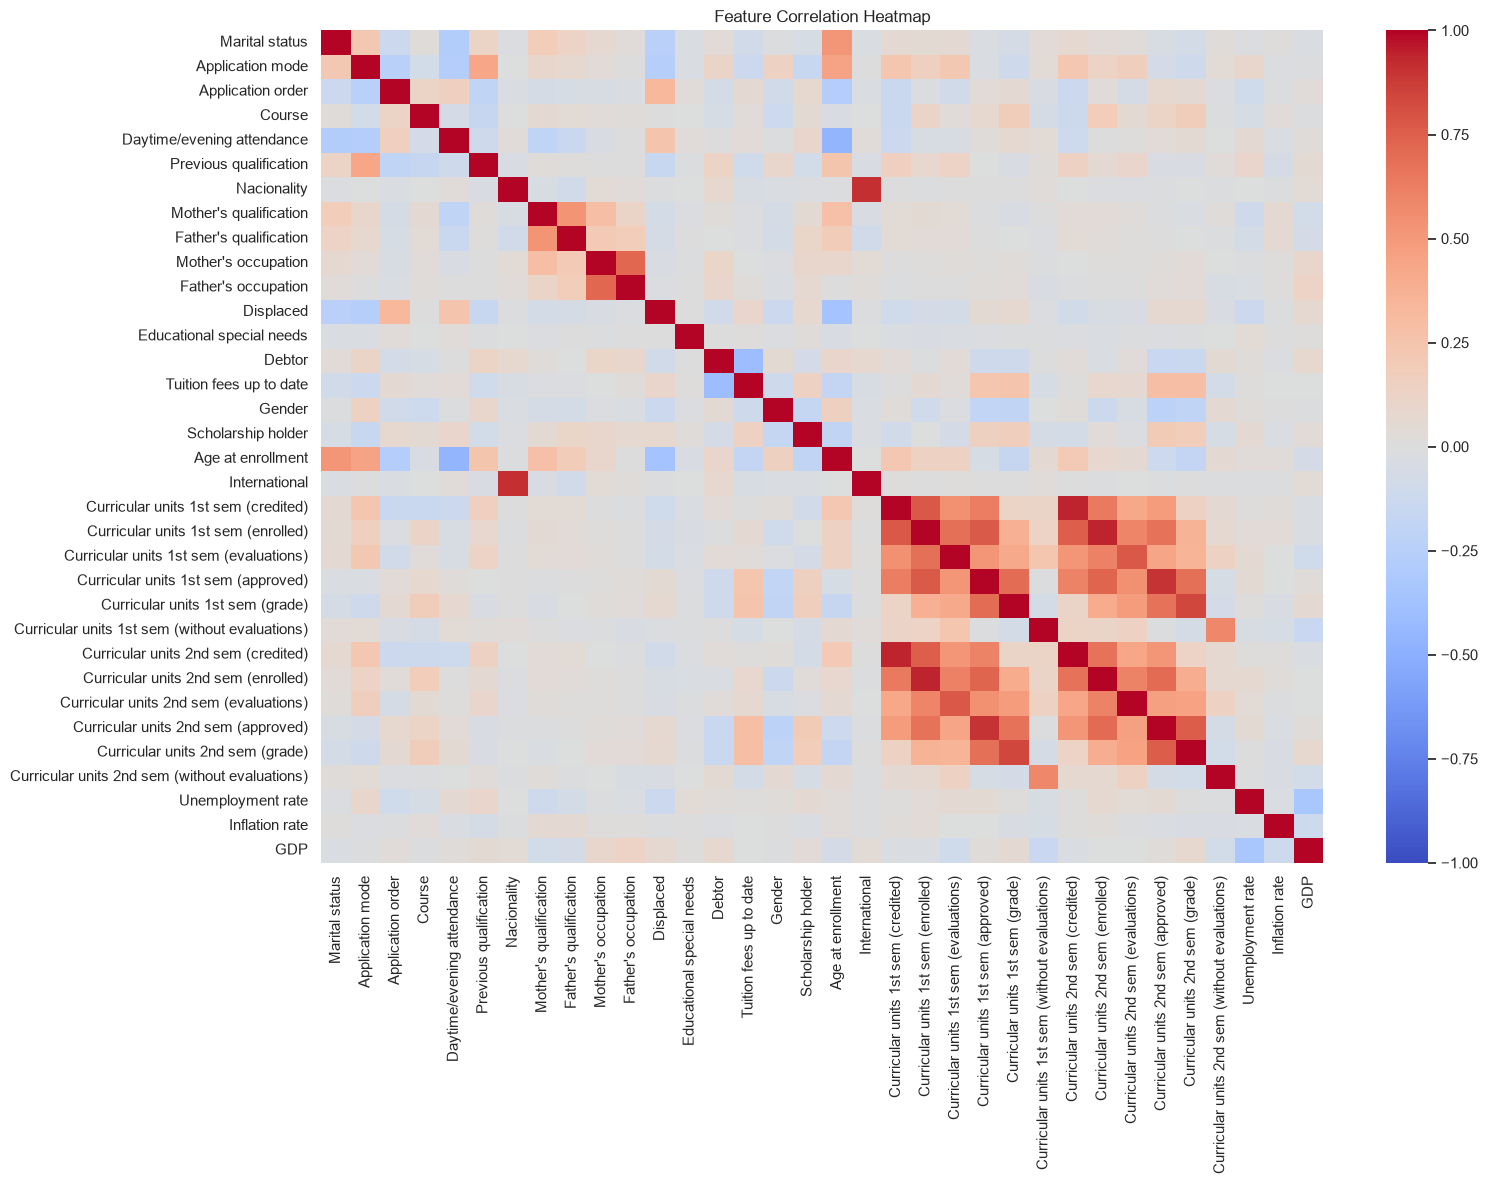

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

correlation = df.drop(columns=["Target"]).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
'''
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_transformer = FunctionTransformer(np.log1p)

preprocessor = ColumnTransformer(
    transformers=[
        ("log", log_transformer, LOG_TRANSFORM_COLS),
        ("scale", StandardScaler(), [
            col for col in CONTINUOUS_COLS
            if col not in LOG_TRANSFORM_COLS
        ]),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])
'''

'\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.preprocessing import FunctionTransformer, StandardScaler\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import LogisticRegression\n\nlog_transformer = FunctionTransformer(np.log1p)\n\npreprocessor = ColumnTransformer(\n    transformers=[\n        ("log", log_transformer, LOG_TRANSFORM_COLS),\n        ("scale", StandardScaler(), [\n            col for col in CONTINUOUS_COLS\n            if col not in LOG_TRANSFORM_COLS\n        ]),\n    ],\n    remainder="passthrough",\n    verbose_feature_names_out=False,\n).set_output(transform="pandas")\n\nmodel = Pipeline([\n    ("preprocessing", preprocessor),\n    ("classifier", LogisticRegression(max_iter=1000)),\n])\n'

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

df_encoded = df_outlier_handled.copy()

X_encoded = df_encoded.drop(columns=["Target"])
y_encoded = df_encoded["Target"]

# Then split and scale
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded,
)

# Perform StandardScaler
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

# Perform PCA
pca = PCA()
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

# Perform LDA
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train_std, y_train)
X_test_lda = lda.transform(X_test_std)


In [11]:
import numpy as np

# PCA + LDA
X_train_combined = np.concatenate(
    [X_train_pca, X_train_lda],
    axis=1,
)

X_test_combined = np.concatenate(
    [X_test_pca, X_test_lda],
    axis=1,
)

print("Original features:", X_train_std.shape[1])
print("PCA components:", X_train_pca.shape[1])
print("LDA components:", X_train_lda.shape[1])
print("Combined features:", X_train_combined.shape[1])

Original features: 236
PCA components: 236
LDA components: 1
Combined features: 237


,Components retained (%),Number of components,Explained variance (%)
0,20,48,45.56
1,50,118,79.75
2,80,189,99.03
3,95,225,100.00


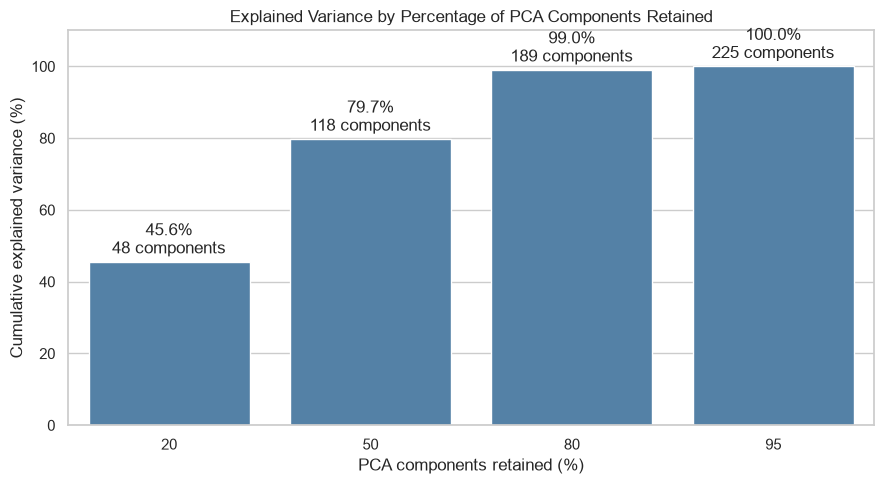

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fit PCA on the standardized training data
pca = PCA()
pca.fit(X_train_std)

# Explained variance of each component
variance = pca.explained_variance_ratio_

# Percentages of components to retain
keep_percentages = [20, 50, 80, 95]

results = []

for pct in keep_percentages:
    n_components = max(1, int(np.ceil(len(variance) * pct / 100)))
    cumulative_variance = variance[:n_components].sum()

    results.append({
        "Components retained (%)": pct,
        "Number of components": n_components,
        "Explained variance (%)": cumulative_variance * 100,
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))

# Plot explained variance retained
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=results_df,
    x="Components retained (%)",
    y="Explained variance (%)",
    color="steelblue",
)

for i, row in results_df.iterrows():
    ax.text(
        i,
        row["Explained variance (%)"] + 1,
        f'{row["Explained variance (%)"]:.1f}%\n'
        f'{int(row["Number of components"])} components',
        ha="center",
        va="bottom",
    )

plt.title("Explained Variance by Percentage of PCA Components Retained")
plt.xlabel("PCA components retained (%)")
plt.ylabel("Cumulative explained variance (%)")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

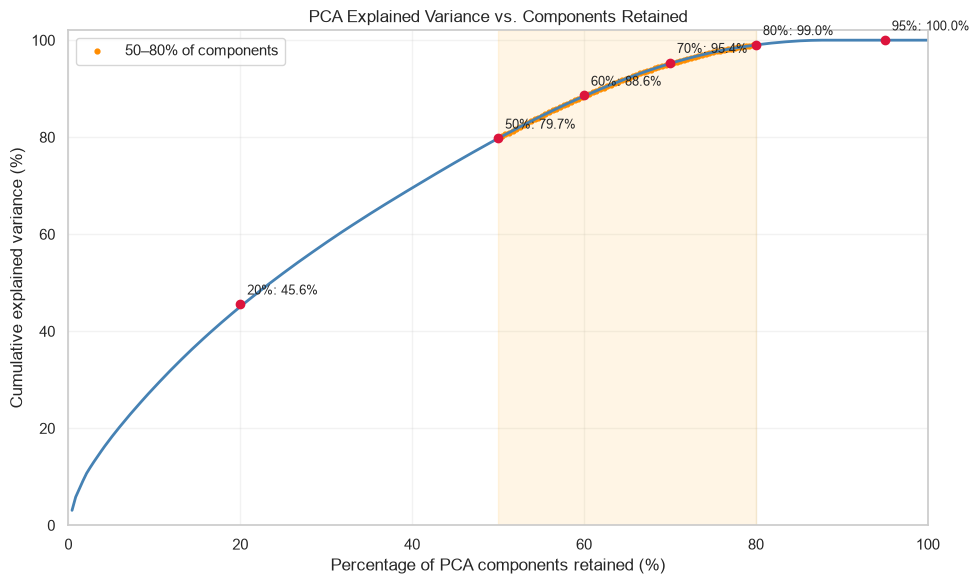

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Cumulative explained variance for every PCA component
cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100

# Percentage of components retained
n_components = len(pca.explained_variance_ratio_)
component_percentages = (
    np.arange(1, n_components + 1) / n_components * 100
)

# Focus on the 50–80% range
mask = (component_percentages >= 50) & (component_percentages <= 80)

plt.figure(figsize=(10, 6))

plt.plot(
    component_percentages,
    cumulative_variance,
    color="steelblue",
    linewidth=2,
)

plt.scatter(
    component_percentages[mask],
    cumulative_variance[mask],
    color="darkorange",
    s=12,
    label="50–80% of components",
)

# Mark the requested percentages
for pct in [20, 50, 60, 70, 80, 95]:
    idx = min(
        int(np.ceil(n_components * pct / 100)) - 1,
        n_components - 1,
    )
    variance = cumulative_variance[idx]

    plt.scatter(pct, variance, color="crimson", zorder=3)
    plt.annotate(
        f"{pct}%: {variance:.1f}%",
        (pct, variance),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9,
    )

plt.axvspan(50, 80, color="orange", alpha=0.10)
plt.xlabel("Percentage of PCA components retained (%)")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA Explained Variance vs. Components Retained")
plt.xlim(0, 100)
plt.ylim(0, 102)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Support Vector Machine (SVM)

A support vector machine classifies by finding the hyperplane that maximizes the margin between the
two classes, with soft-margin slack controlled by `C`. The kernel trick fits non-linear boundaries;
the RBF kernel measures similarity with a `gamma` width. The model is trained on the standardized
features from the previous section, because SVM margins depend on feature scale. Since the binary
subset is imbalanced (more `Graduate` than `Dropout` students), `class_weight="balanced"` weights the
classes inversely to their frequency, and hyperparameters are selected with stratified 5-fold
cross-validation on the training set only, using ROC-AUC as the tuning metric.

In [14]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = [
    {"kernel": ["linear"], "C": [0.01, 0.1, 1, 10]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1]},
]

grid = GridSearchCV(
    SVC(class_weight="balanced", random_state=42),
    param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)
grid.fit(X_train_std, y_train)

cv_results = pd.DataFrame(grid.cv_results_)
cv_summary = (
    cv_results.sort_values("rank_test_score")[
        ["rank_test_score", "param_kernel", "param_C", "param_gamma",
         "mean_test_score", "std_test_score"]
    ]
    .head(8)
    .reset_index(drop=True)
)

print(f"Best parameters: {grid.best_params_}")
print(f"Best CV ROC-AUC: {grid.best_score_:.4f}")
cv_summary.round(4)

Best parameters: {'C': 1, 'kernel': 'linear'}
Best CV ROC-AUC: 0.9490


,rank_test_score,param_kernel,param_C,param_gamma,mean_test_score,std_test_score
0,1,linear,1.00,NaN,0.9490,0.0050
1,2,linear,0.01,NaN,0.9485,0.0043
2,3,linear,0.10,NaN,0.9485,0.0039
3,4,linear,10.00,NaN,0.9481,0.0056
4,5,rbf,10.00,scale,0.9393,0.0065
5,6,rbf,1.00,scale,0.9371,0.0059
6,7,rbf,1.00,0.01,0.9302,0.0079
7,8,rbf,10.00,0.01,0.9221,0.0087


              precision    recall  f1-score   support

     Dropout      0.884     0.859     0.871       284
    Graduate      0.911     0.928     0.919       442

    accuracy                          0.901       726
   macro avg      0.898     0.893     0.895       726
weighted avg      0.901     0.901     0.901       726

Support vectors per class (Dropout, Graduate): [262 421] (23.5% of the training set)


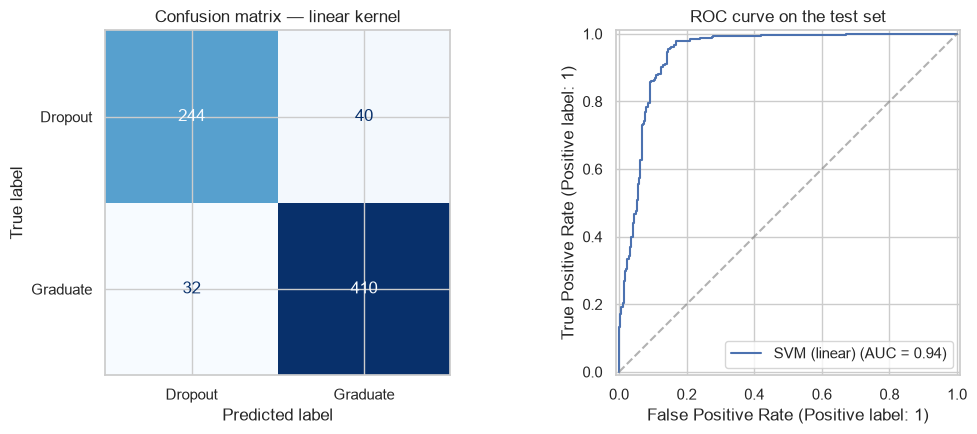

In [15]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

best_svm = grid.best_estimator_
kernel_name = grid.best_params_["kernel"]

y_pred = best_svm.predict(X_test_std)
y_score = best_svm.decision_function(X_test_std)

print(classification_report(
    y_test, y_pred, target_names=["Dropout", "Graduate"], digits=3,
))

n_sv = best_svm.n_support_
print(
    f"Support vectors per class (Dropout, Graduate): {n_sv} "
    f"({n_sv.sum() / len(X_train_std):.1%} of the training set)"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred), display_labels=["Dropout", "Graduate"],
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix — {kernel_name} kernel")

RocCurveDisplay.from_predictions(
    y_test, y_score, ax=axes[1], name=f"SVM ({kernel_name})",
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", alpha=0.6)
axes[1].set_title("ROC curve on the test set")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score

# PCA retaining 95% of the training variance, fitted on the training set only.
pca_95 = PCA(n_components=0.95, svd_solver="full").fit(X_train_std)
X_train_pca95 = pca_95.transform(X_train_std)
X_test_pca95 = pca_95.transform(X_test_std)
print(
    f"PCA 95% variance: {X_train_pca95.shape[1]} of {X_train_std.shape[1]} "
    "features retained"
)

feature_sets = {
    "Standardized (all features)": (X_train_std, X_test_std),
    f"PCA 95% variance ({X_train_pca95.shape[1]} comps)": (X_train_pca95, X_test_pca95),
    "PCA + LDA combined": (X_train_combined, X_test_combined),
}

svm_comparison = []
for name, (X_tr, X_te) in feature_sets.items():
    model = clone(SVC(**grid.best_params_, class_weight="balanced"))
    cv_scores = cross_val_score(model, X_tr, y_train, cv=cv, scoring="roc_auc")
    fitted = model.fit(X_tr, y_train)
    test_auc = roc_auc_score(y_test, fitted.decision_function(X_te))
    svm_comparison.append({
        "Feature set": name,
        "CV ROC-AUC": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "Test ROC-AUC": test_auc,
    })

svm_comparison_df = pd.DataFrame(svm_comparison).set_index("Feature set")
svm_comparison_df.round(4)

PCA 95% variance: 165 of 236 features retained


,CV ROC-AUC,CV std,Test ROC-AUC
Feature set,,,
Standardized (all features),0.9490,0.0050,0.9417
PCA 95% variance (165 comps),0.9201,0.0092,0.9295
PCA + LDA combined,0.9510,0.0054,0.9405


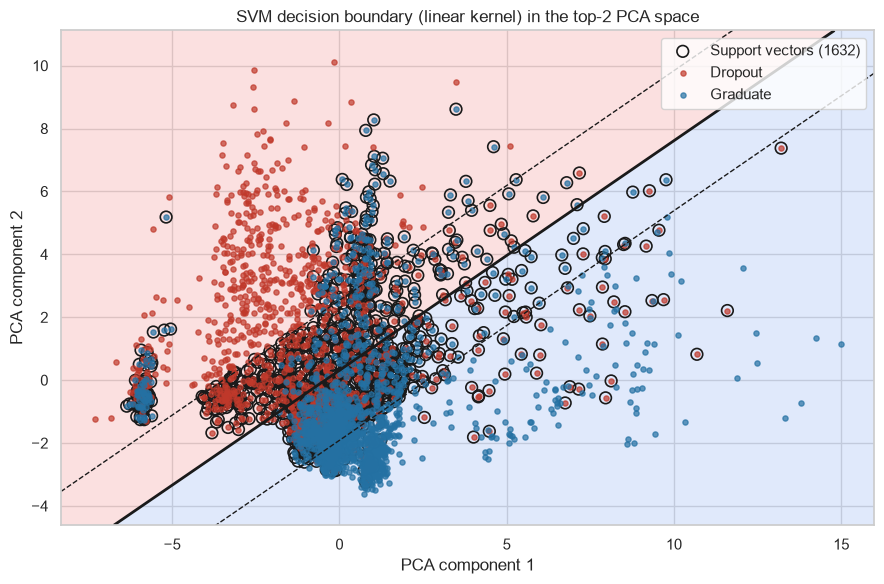

In [17]:
# Decision boundary in the top-2 PCA components (training data).
pca_2d = PCA(n_components=2).fit(X_train_std)
X_train_2d = pca_2d.transform(X_train_std)

svm_2d = SVC(**grid.best_params_, class_weight="balanced").fit(X_train_2d, y_train)

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300),
)
Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(
    xx, yy, np.sign(Z), levels=[-np.inf, 0, np.inf],
    colors=["#f5b3b3", "#b3c9f5"], alpha=0.4,
)
plt.contour(
    xx, yy, Z, levels=[-1, 0, 1], colors="k",
    linestyles=["--", "-", "--"], linewidths=[1, 2, 1],
)

support_vectors = svm_2d.support_vectors_
plt.scatter(
    support_vectors[:, 0], support_vectors[:, 1], s=70,
    facecolors="none", edgecolors="k", linewidths=1.2,
    label=f"Support vectors ({len(support_vectors)})",
)

for label, color, name in [(0, "#c0392b", "Dropout"), (1, "#2471a3", "Graduate")]:
    mask = y_train == label
    plt.scatter(
        X_train_2d[mask, 0], X_train_2d[mask, 1], s=14, c=color,
        label=name, alpha=0.7,
    )

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title(f"SVM decision boundary ({kernel_name} kernel) in the top-2 PCA space")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

**Observations:**

- **A linear boundary is sufficient.** The linear kernel with `C=1` wins the cross-validation
  (ROC-AUC 0.949) ahead of every RBF configuration. In the 236-dimensional standardized space
  (one-hot categories plus curricular-unit counts), the classes are largely linearly separable, and
  the RBF kernel's extra flexibility mainly fits noise — its CV score drops as `gamma` grows.
  The linear CV score is also flat from `C=0.01` to `C=10`, indicating a wide, stable margin: the
  data are separable enough that the slack penalty barely matters.
- **Test performance.** The tuned model reaches 90.1% accuracy (macro F1 0.895) on the held-out test
  set with test ROC-AUC 0.942, close to the CV estimate, so the model generalizes without notable
  overfitting. `Graduate` students are classified more reliably (recall 0.928) than `Dropout`
  students (recall 0.859): the minority class remains harder despite `class_weight="balanced"`.
- **Support vectors.** 683 of 2,904 training points (23.5%) lie on the margin, split 262 `Dropout`
  and 421 `Graduate`. This sizeable fraction shows the classes still overlap around the boundary —
  realistic, since many borderline students share similar academic profiles.
- **Feature representations.** Reducing to the 165 PCA components carrying 95% of the variance
  *hurts* (CV ROC-AUC 0.920 vs 0.949). PCA is unsupervised: it keeps high-variance directions, but
  low-variance components — for example rare one-hot categories — can still be class-discriminative.
  Adding the supervised LDA direction to PCA gives the best CV score (0.951) but no test-set gain
  (0.941 vs 0.942), so the extra dimensionality reduction is not worth the lost interpretability.
  The full standardized feature set is the best choice for this dataset.
